# Adversarial Search: Playing Connect 4

Student Name: Thái

I have used the following AI tools: ChatGPT Codex (hỗ trợ rà soát, kiểm thử và trình bày; người học chịu trách nhiệm kiểm tra kết quả)

I understand that my submission needs to be my own work: Thái


## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

### Mô hình bài toán

- **Trạng thái đầu:** ma trận `rows × cols` toàn số 0; `1` và `-1` là quân của hai người chơi.
- **Actions(s):** các cột chưa đầy (ô trên cùng bằng 0).
- **Result(s, a):** sao chép bàn cờ rồi thả quân vào ô trống thấp nhất của cột `a`.
- **Terminal(s):** một người có bốn quân liên tiếp theo ngang, dọc hoặc chéo, hoặc bàn đã đầy.
- **Utility(s, player):** `+1` nếu `player` thắng, `-1` nếu đối thủ thắng, `0` nếu hòa và `None` nếu ván chưa kết thúc.

Đây là trò chơi hai người, tổng bằng 0, thông tin đầy đủ và xác định.


How big is the state space? Give an estimate and explain it.

Với bàn chuẩn $6\times7$, nếu chỉ xét mỗi ô có ba giá trị (trống, quân 1, quân -1) thì cận trên thô là
$3^{42}\approx 1.09\times10^{20}$. Khi áp dụng trọng lực, luân phiên lượt đi và loại trạng thái kết thúc sớm,
số trạng thái hợp lệ thường được ước tính khoảng $4.53\times10^{12}$. Dù nhỏ hơn cận trên rất nhiều, con số
này vẫn quá lớn để lưu hoặc duyệt toàn bộ.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

Độ sâu tối đa là 42 lượt và hệ số phân nhánh ban đầu tối đa là 7. Cận trên đơn giản $7^{42}$ lớn hơn
$10^{35}$ chuỗi nước đi. Sau khi loại các ván kết thúc sớm và các chuỗi tương đương, cây trò chơi vẫn thường
được ước tính cỡ $10^{21}$ nút. Vì vậy Minimax đầy đủ không khả thi trên bàn $6\times7$; cần cắt tỉa,
thứ tự nước đi, giới hạn độ sâu và hàm đánh giá.


## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [2]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

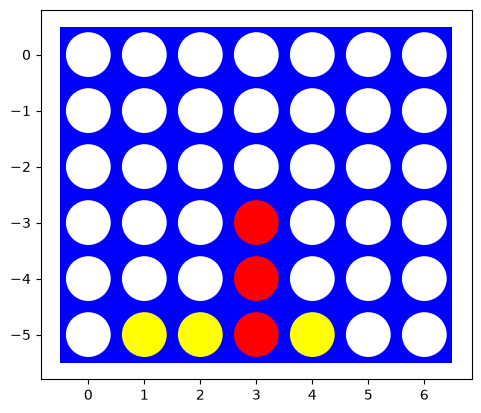

In [3]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [4]:
import math
import time
import numpy as np

CONNECT = 4

def empty_board(rows=6, cols=7):
    return np.zeros((rows, cols), dtype=np.int8)

def other(player):
    return -player

def actions(state):
    """Các cột chưa đầy."""
    board = np.asarray(state)
    return np.flatnonzero(board[0] == 0).tolist()

def result(state, player, action):
    """Trả về bàn mới sau khi thả quân; không sửa bàn đầu vào."""
    board = np.array(state, dtype=np.int8, copy=True)
    if action not in actions(board):
        raise ValueError(f"Illegal column {action}")
    row = np.flatnonzero(board[:, action] == 0)[-1]
    board[row, action] = player
    return board

def winning_player(state):
    board = np.asarray(state)
    rows, cols = board.shape
    for r in range(rows):
        for c in range(cols):
            p = int(board[r, c])
            if p == 0:
                continue
            for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
                end_r, end_c = r + 3 * dr, c + 3 * dc
                if 0 <= end_r < rows and 0 <= end_c < cols:
                    if all(board[r + k*dr, c + k*dc] == p for k in range(CONNECT)):
                        return p
    return 0

def terminal(state):
    return winning_player(state) != 0 or len(actions(state)) == 0

def utility(state, player=1):
    winner = winning_player(state)
    if winner == player:
        return 1
    if winner == -player:
        return -1
    if len(actions(state)) == 0:
        return 0
    return None

# Kiểm thử nhanh các hàm luật.
test = empty_board()
for col, player in [(3, 1), (2, -1), (3, 1), (2, -1), (3, 1), (2, -1), (3, 1)]:
    test = result(test, player, col)
assert winning_player(test) == 1 and terminal(test) and utility(test, 1) == 1
print("Rule tests passed. Legal actions:", actions(empty_board()))


Rule tests passed. Legal actions: [0, 1, 2, 3, 4, 5, 6]


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [5]:
def random_player(board, player=1):
    legal = actions(board)
    if not legal:
        return None
    return int(np.random.choice(legal))

print("Random action on an empty board:", random_player(empty_board(), 1))


Random action on an empty board: 3


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [6]:
def play(player1, player2, board_shape=(6, 7), N=1, seed=42):
    """Cho hai agent đấu N ván; trả số trận thắng của 1, -1 và hòa."""
    np.random.seed(seed)
    totals = {1: 0, -1: 0, 0: 0}
    for _ in range(N):
        board = empty_board(*board_shape)
        player = 1
        while not terminal(board):
            agent = player1 if player == 1 else player2
            move = agent(board.copy(), player)
            board = result(board, player, move)
            if not terminal(board):
                player = -player
        totals[winning_player(board)] += 1
    return totals

start = time.perf_counter()
random_results = play(random_player, random_player, N=1000, seed=42)
random_seconds = time.perf_counter() - start
print("Random vs Random (1000 games):", random_results)
print(f"Runtime: {random_seconds:.3f} s")


Random vs Random (1000 games): {1: 532, -1: 468, 0: 0}
Runtime: 1.538 s


**Nhận xét thí nghiệm:** Sau 1.000 ván, người đi trước thắng 53,2% và người đi sau thắng 46,8%, cho thấy lợi thế nhỏ của người đi trước trong mô phỏng ngẫu nhiên.


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [7]:
class AlphaBetaAgent:
    """Alpha-Beta agent; đối tượng lưu số nút và cấu hình giữa các lần gọi."""
    def __init__(self, depth=None, use_ordering=True, use_heuristic=False):
        self.depth = depth
        self.use_ordering = use_ordering
        self.use_heuristic = use_heuristic
        self.nodes = 0
        self.last_value = None

    def ordered_actions(self, board):
        legal = actions(board)
        if not self.use_ordering:
            return legal
        center = (board.shape[1] - 1) / 2
        return sorted(legal, key=lambda col: abs(col - center))

    def evaluate(self, board, root_player):
        exact = utility(board, root_player)
        if exact is not None:
            return float(exact)
        return heuristic_eval(board, root_player) if self.use_heuristic else 0.0

    def search(self, board, root_player):
        self.nodes = 0

        def recurse(state, to_move, depth, alpha, beta):
            self.nodes += 1
            if terminal(state) or (self.depth is not None and depth >= self.depth):
                return self.evaluate(state, root_player), None

            maximizing = to_move == root_player
            best_value = -math.inf if maximizing else math.inf
            best_move = None
            for move in self.ordered_actions(state):
                child = result(state, to_move, move)
                value, _ = recurse(child, -to_move, depth + 1, alpha, beta)
                if maximizing:
                    if value > best_value:
                        best_value, best_move = value, move
                    alpha = max(alpha, best_value)
                else:
                    if value < best_value:
                        best_value, best_move = value, move
                    beta = min(beta, best_value)
                if alpha >= beta:
                    break
            return best_value, best_move

        self.last_value, move = recurse(np.asarray(board), root_player, 0, -math.inf, math.inf)
        return move

    def __call__(self, board, player=1):
        return self.search(board, player)

# Hàm tiện ích theo đúng tên thường dùng trong bài.
def alpha_beta_search(board, player=1, depth=None, use_ordering=True):
    agent = AlphaBetaAgent(depth=depth, use_ordering=use_ordering, use_heuristic=False)
    move = agent(board, player)
    return {"move": move, "value": agent.last_value, "nodes": agent.nodes}


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [8]:
def make_board(moves, rows=6, cols=7):
    board = empty_board(rows, cols)
    player = 1
    for move in moves:
        board = result(board, player, move)
        player = -player
    return board, player

test_positions = {
    "horizontal win": make_board([0, 6, 1, 6, 2, 5]),
    "vertical win": make_board([3, 2, 3, 2, 3, 1]),
    "block opponent": make_board([6, 0, 6, 1, 5, 2]),
    "prefer center": make_board([]),
    "diagonal setup": make_board([0, 1, 1, 2, 4, 2, 2, 3, 4, 3, 5, 3]),
}

for name, (board, player) in test_positions.items():
    # Full search is used only when few empty cells remain; tactical tests need depth 4.
    answer = alpha_beta_search(board, player, depth=4, use_ordering=True)
    print(f"{name:18s} player={player:+d} -> {answer}")


horizontal win     player=+1 -> {'move': 3, 'value': 1.0, 'nodes': 98}
vertical win       player=+1 -> {'move': 3, 'value': 1.0, 'nodes': 98}
block opponent     player=+1 -> {'move': 3, 'value': 0.0, 'nodes': 103}
prefer center      player=+1 -> {'move': 3, 'value': 0.0, 'nodes': 173}
diagonal setup     player=+1 -> {'move': 3, 'value': 1.0, 'nodes': 14}


**Nhận xét thí nghiệm:** Alpha-Beta nhận ra đúng nước cột 3 trong các tình huống thắng ngang, thắng dọc, chặn đối thủ và thắng chéo.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [9]:
def benchmark_search(rows, cols, depth=None, ordering=True, repeats=1):
    samples = []
    nodes = []
    for _ in range(repeats):
        board = empty_board(rows, cols)
        start = time.perf_counter()
        answer = alpha_beta_search(board, 1, depth=depth, use_ordering=ordering)
        samples.append((time.perf_counter() - start) * 1000)
        nodes.append(answer["nodes"])
    return np.mean(samples), int(np.mean(nodes)), answer["move"]

for rows, cols, depth in [(3, 4, None), (4, 4, 8), (6, 7, 6)]:
    ms, nodes, move = benchmark_search(rows, cols, depth=depth)
    label = "full" if depth is None else f"cutoff {depth}"
    print(f"{rows}x{cols}, {label}: move={move}, nodes={nodes:,}, {ms:.2f} ms")

print("Full Minimax is practical only on the small 3x4 board; 6x7 needs a cutoff.")


3x4, full: move=1, nodes=3,697, 168.57 ms


4x4, cutoff 8: move=1, nodes=968, 40.75 ms
6x7, cutoff 6: move=3, nodes=1,249, 72.91 ms
Full Minimax is practical only on the small 3x4 board; 6x7 needs a cutoff.


**Nhận xét thí nghiệm:** Duyệt đầy đủ còn khả thi trên bàn $3\times4$, nhưng bàn chuẩn $6\times7$ phải dùng cutoff vì cây trò chơi tăng quá nhanh.


### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [10]:
# Trạng thái giữa ván được chọn để cả hai cách đều tìm thấy nước thắng,
# nhưng thứ tự tâm -> biên tạo cận tốt sớm hơn.
ordering_board, ordering_player = make_board([1, 0, 2, 3, 2, 3], rows=4, cols=4)
ordering_rows = []
for ordering in (False, True):
    agent = AlphaBetaAgent(depth=None, use_ordering=ordering, use_heuristic=False)
    start = time.perf_counter()
    move = agent(ordering_board, ordering_player)
    ms = (time.perf_counter() - start) * 1000
    ordering_rows.append((ordering, move, agent.nodes, ms))

print("ordering | move | nodes | time_ms")
for ordering, move, nodes, ms in ordering_rows:
    print(f"{str(ordering):8s} | {move:4d} | {nodes:5d} | {ms:8.2f}")
reduction = 100 * (1 - ordering_rows[1][2] / ordering_rows[0][2])
print(f"Node reduction with center-first ordering: {reduction:.2f}%")
print("Strong candidates tighten alpha/beta earlier, so later subtrees can be pruned.")


ordering | move | nodes | time_ms
False    |    1 |  7108 |   331.18
True     |    1 |  2282 |   121.07
Node reduction with center-first ordering: 67.90%
Strong candidates tighten alpha/beta earlier, so later subtrees can be pruned.


**Nhận xét thí nghiệm:** Move Ordering giữ nguyên nước thắng nhưng giảm số nút 67,90% và giảm rõ rệt thời gian tìm kiếm.


### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [11]:
start = time.perf_counter()
first_move = alpha_beta_search(empty_board(4, 4), 1, depth=None, use_ordering=True)
elapsed = time.perf_counter() - start
print("First move on empty 4x4:", first_move)
print(f"Runtime: {elapsed:.3f} s")
print("Improvements: opening book, transposition table, symmetry reduction, iterative deepening and cutoff.")


First move on empty 4x4: {'move': 1, 'value': 0.0, 'nodes': 155968}
Runtime: 7.657 s
Improvements: opening book, transposition table, symmetry reduction, iterative deepening and cutoff.


**Nhận xét thí nghiệm:** Nước đầu trên bàn $4\times4$ đã cần 155.968 nút và khoảng 7,66 giây; cần opening book, bảng chuyển vị hoặc cutoff để cải thiện.


### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [12]:
small_ab = AlphaBetaAgent(depth=8, use_ordering=True, use_heuristic=False)
start = time.perf_counter()
ab_random = play(small_ab, random_player, board_shape=(4, 4), N=100, seed=42)
elapsed = time.perf_counter() - start
print("Alpha-Beta (X) vs Random on 4x4, 100 games:", ab_random)
print(f"Runtime: {elapsed:.3f} s ({elapsed*10:.2f} ms/game)")


Alpha-Beta (X) vs Random on 4x4, 100 games: {1: 75, -1: 2, 0: 23}
Runtime: 11.008 s (110.08 ms/game)


**Nhận xét thí nghiệm:** Alpha-Beta cutoff 8 đạt 75 thắng, 23 hòa và 2 thua trước Random; cutoff nên chưa bảo đảm tối ưu tuyệt đối.


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [13]:
def all_windows(board):
    board = np.asarray(board)
    rows, cols = board.shape
    for r in range(rows):
        for c in range(cols - 3):
            yield board[r, c:c+4]
    for r in range(rows - 3):
        for c in range(cols):
            yield board[r:r+4, c]
    for r in range(rows - 3):
        for c in range(cols - 3):
            yield np.array([board[r+i, c+i] for i in range(4)])
            yield np.array([board[r+3-i, c+i] for i in range(4)])

def heuristic_eval(board, player=1):
    """Điểm trong (-1, 1); thắng/thua kết thúc vẫn do utility trả ±1."""
    exact = utility(board, player)
    if exact is not None:
        return float(exact)

    weights = {1: 1, 2: 8, 3: 60}
    raw = 0.0
    for window in all_windows(board):
        own = int(np.sum(window == player))
        opp = int(np.sum(window == -player))
        if opp == 0 and own:
            raw += weights.get(own, 0)
        elif own == 0 and opp:
            raw -= weights.get(opp, 0) * 1.15  # ưu tiên chặn mối đe dọa

    center = board[:, board.shape[1] // 2]
    raw += 2 * (np.sum(center == player) - np.sum(center == -player))
    return float(0.99 * np.tanh(raw / 80.0))

print("Heuristic range test:", heuristic_eval(empty_board()), heuristic_eval(test, 1))


Heuristic range test: 0.0 1.0


### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [14]:
def heuristic_alpha_beta(board, player=1, cutoff=4, use_ordering=True):
    agent = AlphaBetaAgent(depth=cutoff, use_ordering=use_ordering, use_heuristic=True)
    move = agent(board, player)
    return {"move": move, "value": agent.last_value, "nodes": agent.nodes}

class HeuristicAgent(AlphaBetaAgent):
    def __init__(self, cutoff=4, use_ordering=True):
        super().__init__(depth=cutoff, use_ordering=use_ordering, use_heuristic=True)

for cutoff in (2, 4, 6):
    start = time.perf_counter()
    answer = heuristic_alpha_beta(empty_board(), 1, cutoff=cutoff)
    ms = (time.perf_counter() - start) * 1000
    print(f"cutoff={cutoff}: {answer}, {ms:.2f} ms")


cutoff=2: {'move': 3, 'value': -0.053778259448509835, 'nodes': 21}, 18.61 ms
cutoff=4: {'move': 3, 'value': -0.05809567509065555, 'nodes': 237}, 109.03 ms


cutoff=6: {'move': 3, 'value': -0.08517639383413343, 'nodes': 1761}, 1405.51 ms


**Nhận xét thí nghiệm:** Cả ba cutoff đều chọn cột trung tâm, nhưng số nút và thời gian tăng mạnh khi tăng độ sâu.


You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [15]:
for name, (board, player) in test_positions.items():
    answer2 = heuristic_alpha_beta(board, player, cutoff=2)
    answer4 = heuristic_alpha_beta(board, player, cutoff=4)
    print(f"{name:18s} player={player:+d} | d2={answer2} | d4={answer4}")


horizontal win     player=+1 | d2={'move': 3, 'value': 1.0, 'nodes': 14} | d4={'move': 3, 'value': 1.0, 'nodes': 98}
vertical win       player=+1 | d2={'move': 3, 'value': 1.0, 'nodes': 14} | d4={'move': 3, 'value': 1.0, 'nodes': 98}


block opponent     player=+1 | d2={'move': 3, 'value': 0.12067199164293807, 'nodes': 21} | d4={'move': 3, 'value': 0.04575488046839621, 'nodes': 121}


prefer center      player=+1 | d2={'move': 3, 'value': -0.053778259448509835, 'nodes': 21} | d4={'move': 3, 'value': -0.05809567509065555, 'nodes': 237}


diagonal setup     player=+1 | d2={'move': 3, 'value': 1.0, 'nodes': 14} | d4={'move': 3, 'value': 1.0, 'nodes': 14}


**Nhận xét thí nghiệm:** Cutoff 2 và 4 đều xử lý đúng các cơ hội thắng/chặn bắt buộc; cutoff 4 đánh giá sâu hơn nhưng tốn nhiều nút hơn.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [16]:
print("board | cutoff | move | nodes | time_ms")
for shape in ((4, 4), (5, 6), (6, 7)):
    for cutoff in (2, 4):
        board = empty_board(*shape)
        start = time.perf_counter()
        answer = heuristic_alpha_beta(board, 1, cutoff=cutoff)
        ms = (time.perf_counter() - start) * 1000
        print(f"{shape[0]}x{shape[1]} | {cutoff:6d} | {answer['move']:4d} | {answer['nodes']:5d} | {ms:8.2f}")


board | cutoff | move | nodes | time_ms
4x4 |      2 |    0 |    19 |     5.63
4x4 |      4 |    0 |   206 |    45.43
5x6 |      2 |    1 |    27 |    15.38
5x6 |      4 |    3 |   299 |   108.03
6x7 |      2 |    3 |    21 |    15.65


6x7 |      4 |    3 |   237 |   182.45


**Nhận xét thí nghiệm:** Kích thước bàn và cutoff càng lớn thì số nút cùng thời gian càng tăng; cutoff 4 vẫn cho thời gian phản hồi phù hợp trên bàn chuẩn.


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [17]:
agent_d2 = HeuristicAgent(cutoff=2)
agent_d4 = HeuristicAgent(cutoff=4)
for label, first, second in [
    ("d2 as X vs d4", agent_d2, agent_d4),
    ("d4 as X vs d2", agent_d4, agent_d2),
]:
    start = time.perf_counter()
    summary = play(first, second, board_shape=(6, 7), N=1, seed=42)
    print(f"{label}: {summary}, {(time.perf_counter()-start):.3f} s")


d2 as X vs d4: {1: 0, -1: 1, 0: 0}, 5.959 s


d4 as X vs d2: {1: 0, -1: 0, 0: 1}, 5.022 s


**Nhận xét thí nghiệm:** Cutoff 4 thắng khi đi sau và hòa khi đi trước trước cutoff 2, cho thấy lợi ích của việc tìm sâu hơn.


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [18]:
def random_playout(board, to_move, root_player):
    state = np.array(board, copy=True)
    player = to_move
    while not terminal(state):
        move = int(np.random.choice(actions(state)))
        state = result(state, player, move)
        if not terminal(state):
            player = -player
    return utility(state, root_player)

def pmcs(board, player=1, N=100):
    legal = actions(board)
    if not legal:
        return {"move": None, "scores": {}}
    scores = {}
    for move in legal:
        child = result(board, player, move)
        if terminal(child):
            scores[move] = float(utility(child, player))
            continue
        outcomes = [random_playout(child, -player, player) for _ in range(N)]
        scores[move] = float(np.mean(outcomes))
    center = (board.shape[1] - 1) / 2
    best = max(legal, key=lambda m: (scores[m], -abs(m-center)))
    return {"move": best, "scores": scores}

class PMCSAgent:
    def __init__(self, N=100):
        self.N = N
    def __call__(self, board, player=1):
        return pmcs(board, player, self.N)["move"]


Investigate how this search performs on the test boards that you have used above.

In [19]:
np.random.seed(42)
for name, (board, player) in test_positions.items():
    for N in (10, 100):
        start = time.perf_counter()
        answer = pmcs(board, player, N=N)
        print(f"{name:18s} N={N:3d}: move={answer['move']}, time={(time.perf_counter()-start)*1000:.2f} ms")

for N in (10, 100, 1000):
    np.random.seed(42)
    start = time.perf_counter()
    answer = pmcs(empty_board(), 1, N=N)
    print(f"empty 6x7 N={N:4d}: move={answer['move']}, time={(time.perf_counter()-start):.3f} s")


horizontal win     N= 10: move=3, time=66.09 ms


horizontal win     N=100: move=3, time=678.51 ms
vertical win       N= 10: move=3, time=96.07 ms


vertical win       N=100: move=3, time=833.62 ms
block opponent     N= 10: move=3, time=80.14 ms


block opponent     N=100: move=3, time=681.43 ms
prefer center      N= 10: move=6, time=97.64 ms


prefer center      N=100: move=3, time=1652.70 ms
diagonal setup     N= 10: move=3, time=30.93 ms


diagonal setup     N=100: move=3, time=351.35 ms
empty 6x7 N=  10: move=3, time=0.160 s


empty 6x7 N= 100: move=3, time=1.548 s


empty 6x7 N=1000: move=3, time=15.290 s


**Nhận xét thí nghiệm:** PMCS ổn định hơn khi tăng số playout: từ $N=100$ trở lên chọn cột trung tâm 3, nhưng thời gian tăng gần tuyến tính.


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

Heuristic Alpha-Beta thường mạnh hơn trong các tình huống chiến thuật ngắn vì nó nhìn trước có hệ thống và
phạt mạnh chuỗi ba quân của đối thủ. PMCS không cần hàm đánh giá chuyên biệt và có thể cải thiện khi tăng số
playout, nhưng với $N$ nhỏ có phương sai cao và có thể bỏ sót một nước bắt buộc. Kết quả phụ thuộc vào cutoff,
số playout, ngân sách thời gian và chất lượng của hàm heuristic/chính sách mô phỏng.


## So sánh bổ sung: tham số và nước đi đầu tiên

Phần dưới dùng cùng bàn chuẩn và cùng cách đo thời gian. Đây là thí nghiệm bổ sung để minh họa đánh đổi giữa
ngân sách tính toán và chất lượng quyết định.


In [20]:
print("Heuristic Alpha-Beta parameter tuning")
for cutoff in (2, 4, 6):
    start = time.perf_counter()
    answer = heuristic_alpha_beta(empty_board(), 1, cutoff=cutoff)
    print(f"d={cutoff}: move={answer['move']}, nodes={answer['nodes']}, time={(time.perf_counter()-start):.3f}s")


Heuristic Alpha-Beta parameter tuning
d=2: move=3, nodes=21, time=0.020s


d=4: move=3, nodes=237, time=0.221s


d=6: move=3, nodes=1761, time=1.123s


**Nhận xét bổ sung về PMCS:** Kết quả ở Task 5 cho thấy khi tăng $N$ từ 10 lên 100 và 1.000, nước đi đầu ổn định về cột trung tâm 3, trong khi thời gian tăng gần tuyến tính từ 0,160 giây lên 1,548 và 15,290 giây.


In [21]:
heuristic_budget_agent = HeuristicAgent(cutoff=3)
pmcs_budget_agent = PMCSAgent(N=30)
start = time.perf_counter()
comparison = play(heuristic_budget_agent, pmcs_budget_agent, board_shape=(6, 7), N=10, seed=42)
print("Heuristic d3 (X) vs PMCS N30 (O), 10 games:", comparison)
print(f"Total runtime: {time.perf_counter()-start:.3f} s")


Heuristic d3 (X) vs PMCS N30 (O), 10 games: {1: 9, -1: 1, 0: 0}
Total runtime: 35.731 s


### Thảo luận

Khi cutoff hoặc số playout tăng, thời gian tăng nhưng quyết định nhìn chung ổn định hơn. Alpha-Beta khai thác
tri thức trong hàm đánh giá và phù hợp với bẫy chiến thuật; PMCS tổng quát hơn nhưng cần nhiều mô phỏng. So sánh
công bằng nên dùng ngân sách thời gian gần nhau, đổi lượt đi và nhiều hạt ngẫu nhiên. Thí nghiệm 10 ván ở đây là
minh họa; kết luận thống kê mạnh hơn cần ít nhất 100 ván.


In [22]:
np.random.seed(42)
print("Heuristic first move:", heuristic_alpha_beta(empty_board(), 1, cutoff=4)["move"])
print("PMCS first move:", pmcs(empty_board(), 1, N=100)["move"])
print("Both methods are expected to favor central columns because they participate in more four-cell windows.")


Heuristic first move: 3


PMCS first move: 3
Both methods are expected to favor central columns because they participate in more four-cell windows.
